# Laboratorio 2
**Redes Neuronales para Lenguaje Natural, 2026**

En este laboratorio construiremos un sistema que, a partir de instrucciones en lenguaje natural, genere programas para dibujar escenas geométricas. Utilizaremos un modelo de lenguaje preentrenado y estudiaremos distintas estrategias para resolver la tarea: **zero-shot, prompting y fine-tuning mediante LoRA**.

**Entrega: 23 de noviembre de 2026**

**Formato: notebook de Python (.ipynb)**

**No olvidar mantener todas las salidas de cada región de código en el notebook!**

---


## 0. Preparación del entorno

Este laboratorio está pensado para ejecutarse en Google Colab con GPU (Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU).

Comenzamos instalando e importando las bibliotecas que utilizaremos a lo largo del laboratorio.


In [1]:
# En algunos entornos Colab viene una versión antigua de torchao que interfiere con PEFT.
%pip uninstall -y torchao

# Dependencias del laboratorio. Qwen3.5 requiere transformers>=5.2.
%pip install -q -U 'numpy>=1.26,<2' 'pandas>=2.1,<2.3' 'matplotlib>=3.8,<3.10'
%pip install -q 'transformers==5.2.0' 'accelerate>=1.1,<2' 'peft>=0.18,<1'

# PyTorch: en Colab ya viene; en local lo instalamos si falta.
import importlib.util
if importlib.util.find_spec('torch') is None:
    %pip install -q torch

# En Mac Intel (torch 2.2.x) aplicamos parches de compatibilidad para transformers 5.2.
import torch
if tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2]) < (2, 4):
    %run patch_transformers_macintel.py


Note: you may need to restart the kernel to use updated packages.


c:\Users\k744571\Dropbox\MCDAA_Maestria\RNLN\lab2\.venv-win\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


The system cannot find the file specified.
The system cannot find the file specified.


Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle, Polygon

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

GRID_SIZE = 6

print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'no disponible')


c:\Users\k744571\Dropbox\MCDAA_Maestria\RNLN\lab2\.venv-win\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


GPU: no disponible


### 0.1. Un lenguaje para dibujar escenas

En lugar de generar directamente una imagen, el modelo deberá producir un programa en un pequeño lenguaje de dominio específico (DSL - Domain-Specific Language). Cada línea describe un objeto de la forma:

```text
FIGURA COLOR X Y TAMAÑO
```

- `FIGURA` puede ser `CIRCLE` (círculo), `SQUARE` (cuadrado) o `TRIANGLE` (triángulo).
- `COLOR` puede ser `RED` (rojo), `BLUE` (azul), `GREEN` (verde) o `YELLOW` (amarillo).
- `X` e `Y` son enteros entre 0 y 5. El origen `(0,0)` está en la esquina superior izquierda. X crece hacia la derecha e Y hacia abajo.
- `TAMAÑO` es un entero entre 1 y 6. Indica que el objeto ocupa una superficie equivalente a un cuadrado de `TAMAÑO x TAMAÑO` celdas.
- `(X,Y)` corresponde a la esquina superior izquierda de esa superficie. La figura crece hacia abajo y hacia la derecha.
- Todos los objetos deben quedar completamente dentro del tablero de 6x6.
- Una escena contiene entre 1 y 3 objetos, y sus superficies no pueden superponerse.

**Importante:** para determinar colisiones, todas las figuras ocupan una superficie cuadrada (que le llamamos "huella"), incluso los círculos y los triángulos.


Por ejemplo:

```text
SQUARE BLUE 1 1 2
CIRCLE RED 3 1 1
```

El cuadrado azul ocupa la región de (1,1) a (2,2), mientras que el círculo rojo ocupa la celda (3,1), como se ve en la siguiente imagen:

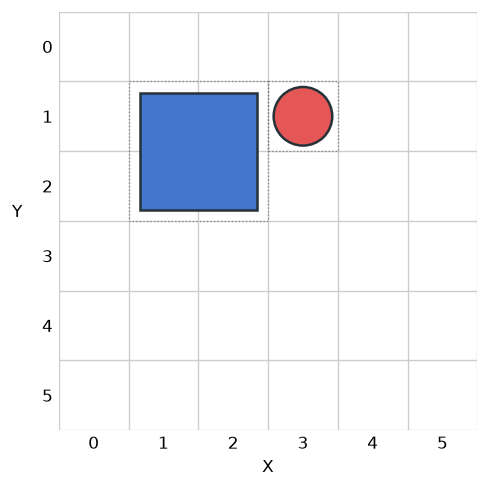


Notar que el orden de las líneas no modifica la escena. Por ese motivo, evaluaremos los dibujos representados, no la igualdad literal entre programas.

Las funciones de interpretación y visualización del DSL se proveen a continuación.


In [3]:
# Una escena es una lista de tuplas (FIGURA, COLOR, X, Y, TAMAÑO).
SHAPES = ('CIRCLE', 'SQUARE', 'TRIANGLE')
COLORS = ('RED', 'BLUE', 'GREEN', 'YELLOW')

COLOR_HEX = {
    'RED': '#e45756',
    'BLUE': '#4277cd',
    'GREEN': '#43a77c',
    'YELLOW': '#e6ba48',
}

class SceneError(ValueError):
    '''La salida no cumple con la gramática o restricciones de la DSL.'''


def validate_scene(scene):
    occupied = set()

    for obj in scene:
        if len(obj) != 5:
            raise SceneError('Cada objeto necesita FIGURA COLOR X Y TAMAÑO.')

        shape, color, x, y, size = obj

        if shape not in SHAPES or color not in COLORS:
            raise SceneError(f'Figura o color desconocidos: {shape} {color}.')

        if any(type(v) is not int for v in (x, y, size)):
            raise SceneError('X, Y y TAMAÑO deben ser enteros.')

        if not (1 <= size <= GRID_SIZE):
            raise SceneError(f'Tamaño inválido: {size}.')

        if x < 0 or y < 0 or x + size > GRID_SIZE or y + size > GRID_SIZE:
            raise SceneError(
                f'Objeto fuera del tablero: ({x}, {y}), tamaño {size}.'
            )

        # Todas las celdas reservadas por el objeto.
        footprint = {
            (col, row)
            for col in range(x, x + size)
            for row in range(y, y + size)
        }

        if occupied & footprint:
            raise SceneError(
                f'Colisión entre objetos en {sorted(occupied & footprint)}.'
            )

        occupied.update(footprint)

    return True


def parse_scene(program):
    '''Convierte el programa DSL en una lista de objetos de cinco atributos.'''
    if not isinstance(program, str) or not program.strip():
        raise SceneError('El programa está vacío.')

    objects = []

    for num, line in enumerate(program.strip().splitlines(), start=1):
        fields = line.strip().split()

        if len(fields) != 5:
            raise SceneError(
                f'Línea {num}: se esperaban 5 campos, '
                f'se recibieron {len(fields)}.'
            )

        shape, color, xs, ys, ss = fields

        try:
            x, y, size = int(xs), int(ys), int(ss)
        except ValueError as e:
            raise SceneError(
                f'Línea {num}: X, Y y TAMAÑO deben ser enteros.'
            ) from e

        objects.append((shape, color, x, y, size))

    validate_scene(objects)
    return objects


def scene_to_dsl(scene):
    '''Serializa en orden estable: Y, X, FIGURA, COLOR, TAMAÑO.'''
    validate_scene(scene)

    ordered = sorted(
        scene,
        key=lambda obj: (obj[3], obj[2], obj[0], obj[1], obj[4])
    )

    return '\n'.join(
        f'{shape} {color} {x} {y} {size}'
        for shape, color, x, y, size in ordered
    )


In [4]:
def render_scene(scene_or_program, ax=None, title=None):
    '''Dibuja una escena con objetos de tamaño variable.'''
    scene = (
        parse_scene(scene_or_program)
        if isinstance(scene_or_program, str)
        else scene_or_program
    )
    validate_scene(scene)

    if ax is None:
        fig, ax = plt.subplots(figsize=(5, 5))
    else:
        fig = ax.figure

    ax.set_xlim(0, GRID_SIZE)
    ax.set_ylim(GRID_SIZE, 0)
    ax.set_aspect('equal')

    for k in range(GRID_SIZE + 1):
        ax.axvline(k, color='#cccccc', linewidth=0.8, zorder=0)
        ax.axhline(k, color='#cccccc', linewidth=0.8, zorder=0)

    for shape, color, x, y, size in scene:
        cx, cy = x + size / 2, y + size / 2
        margin = 0.08 * size

        kwargs = {
            'facecolor': COLOR_HEX[color],
            'edgecolor': '#263238',
            'linewidth': 1.5,
            'zorder': 2,
        }

        if shape == 'CIRCLE':
            patch = Circle(
                (cx, cy),
                0.42 * size,
                **kwargs
            )

        elif shape == 'SQUARE':
            patch = Rectangle(
                (x + margin, y + margin),
                size - 2 * margin,
                size - 2 * margin,
                **kwargs
            )

        else:
            patch = Polygon(
                [
                    (cx, y + margin),
                    (x + margin, y + size - margin),
                    (x + size - margin, y + size - margin)
                ],
                closed=True,
                **kwargs
            )

        ax.add_patch(patch)

        # Contorno de la superficie reservada por el objeto.
        ax.add_patch(
            Rectangle(
                (x, y),
                size,
                size,
                fill=False,
                edgecolor='#555555',
                linestyle=':',
                linewidth=0.8,
                alpha=0.6,
                zorder=3
            )
        )

    ax.set_xticks(
        [i + 0.5 for i in range(GRID_SIZE)],
        labels=range(GRID_SIZE)
    )
    ax.set_yticks(
        [i + 0.5 for i in range(GRID_SIZE)],
        labels=range(GRID_SIZE)
    )

    ax.tick_params(length=0)
    ax.set_xlabel('X')
    ax.set_ylabel('Y', rotation=0, labelpad=15)

    if title:
        ax.set_title(title)

    for spine in ax.spines.values():
        spine.set_visible(False)

    return fig, ax


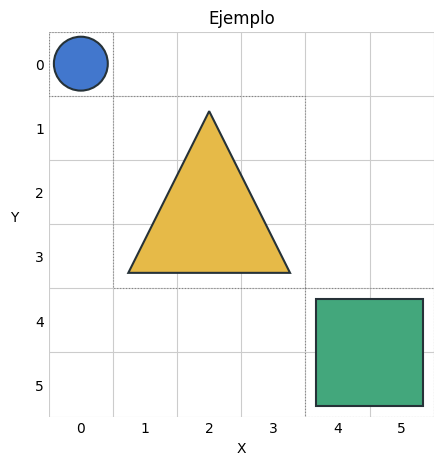

In [5]:
# Ejemplo de un programa renderizado
program = """
CIRCLE BLUE 0 0 1
TRIANGLE YELLOW 1 1 3
SQUARE GREEN 4 4 2
"""

fig, ax = render_scene(program, title='Ejemplo')


### 0.2. Dataset

Trabajaremos con un dataset de 1200 pares `(instrucción, programa)`. Las instrucciones están escritas en español y fueron generadas sintéticamente usando el LLM GPT 6.1 Sol High (OpenAI).

Las particiones se dividen en: 960 ejemplos de entrenamiento (`train`), 120 de desarrollo (`dev`) y 120 de test (`test`).

- `train`: 960 ejemplos, se pueden utilizar para ejemplos few-shot y para hacer fine-tuning.
- `dev`: 120 ejemplos, se pueden utilizar para diseñar prompts, seleccionar hiperparámetros y analizar errores.
- `test`: 120 ejemplos, se reservan para la evaluación final.

Cada dataframe contiene `id`, `instruccion` y `programa` (ground truth).

Además, tendremos el conjunto `test_ood`, que contiene 50 ejemplos con instrucciones muy diferentes a las que se encuentran en los conjuntos anteriores. Hay instrucciones como: _"Hacé una casa de dos piezas: (...) Sumá un sol, círculo amarillo tamaño 1, en (5,0)."_, en las que se describe un escena que representa algo real, e instrucciones como: _"Dibujá seis figuras de una casilla en zigzag..."_, en las que superamos el límite de tres figuras por escena. Este conjunto no lo utilizaremos hasta la parte final del notebook, para medir la capacidad de nuestros métodos para generalizar a escenas fuera de distribución.


In [6]:
#@title Cargar datos del laboratorio

from pathlib import Path
import zipfile

DATASET_ZIP = 'RNLN_2026_lab2_splits.zip'

# En Colab, si el archivo todavía no está, solicitarlo
if not Path(DATASET_ZIP).exists():
    try:
        from google.colab import files
        print('Subí el archivo:', DATASET_ZIP)
        files.upload()
    except ImportError as e:
        raise FileNotFoundError(
            f'No se encontró {DATASET_ZIP}. Colocalo en el directorio de trabajo.'
        ) from e

# Extraer las cuatro particiones
Path('data').mkdir(exist_ok=True)

with zipfile.ZipFile(DATASET_ZIP) as z:
    for split in ('train', 'dev', 'test', 'test_ood'):
        filename = f'data/{split}.csv'
        Path(filename).write_bytes(z.read(filename))

print('Dataset cargado correctamente.')


Dataset cargado correctamente.


Train: 960 | Dev: 120 | Test: 120 | Test OOD: 50

Ejemplo de instrucción:
Todo azul: círculo tamaño 1 en el origen, círculo tamaño 2 en (1,1), triángulo tamaño 1 en (4,4).

Programa de referencia:
CIRCLE BLUE 0 0 1
CIRCLE BLUE 1 1 2
TRIANGLE BLUE 4 4 1


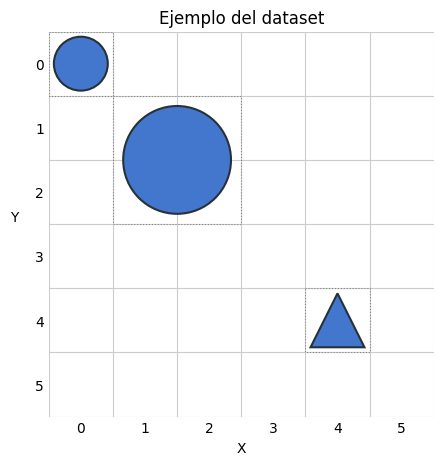

In [7]:
train_df = pd.read_csv('data/train.csv')
dev_df = pd.read_csv('data/dev.csv')
test_df = pd.read_csv('data/test.csv')
test_ood_df = pd.read_csv('data/test_ood.csv')

print('Train:', len(train_df), '| Dev:', len(dev_df), '| Test:', len(test_df), '| Test OOD:', len(test_ood_df))
print('\nEjemplo de instrucción:')
print(train_df.iloc[0]['instruccion'])
print('\nPrograma de referencia:')
print(train_df.iloc[0]['programa'])
render_scene(train_df.iloc[0]['programa'], title='Ejemplo del dataset')
plt.show()


### 0.3. Funciones de evaluación

Utilizaremos las siguientes métricas para comparar los modelos y las estrategias:

- **Validez:** proporción de programas generados que cumplen la gramática y las restricciones del DSL.
- **Accuracy:** proporción de escenas generadas que coinciden exactamente con el dibujo de referencia (sin importar el orden de las líneas).
- **F1 de objetos:** media armónica entre precisión y recall de las tuplas `(FIGURA, COLOR, X, Y, TAMAÑO)`. Una salida inválida recibe F1 = 0.

Se proporciona una función que recibe un dataframe con ejemplos y una lista de predicciones en el mismo orden. También incluimos una función para visualizar las diferencias entre una predicción y la referencia.


In [8]:
def evaluate_predictions(examples_df, predictions):
    if len(examples_df) != len(predictions):
        raise ValueError('Debe haber una predicción por cada instrucción.')
    rows = []
    for (_, row), prediction in zip(examples_df.iterrows(), predictions):
        gold = set(parse_scene(row['programa']))
        valid, exact, f1, error = False, False, 0.0, ''
        try:
            predicted = set(parse_scene(prediction))
            valid = True
            exact = gold == predicted
            f1 = 2 * len(gold & predicted) / (len(gold) + len(predicted))
        except SceneError as e:
            error = str(e)
        rows.append({
            'id': row['id'], 'instruccion': row['instruccion'],
            'referencia': row['programa'], 'prediccion': prediction,
            'valido': valid, 'exacto': exact, 'f1_objetos': f1, 'error': error,
        })
    return pd.DataFrame(rows)


def show_metrics(results, name='Resultados'):
    print(f'{name} (N = {len(results)})')
    print(f'Validez:    {results.valido.mean():.1%}')
    print(f'Accuracy:   {results.exacto.mean():.1%}')
    print(f'F1 objetos: {results.f1_objetos.mean():.3f}')


In [9]:
def compare_drawings(results, index=0):
    row = results.iloc[index]
    fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
    render_scene(row.referencia, ax=axes[0], title='Referencia')
    if row.valido:
        render_scene(row.prediccion, ax=axes[1], title='Predicción')
    else:
        axes[1].axis('off')
        axes[1].text(0.02, 0.65, 'Generación inválida', fontsize=15,
                     transform=axes[1].transAxes)
        axes[1].text(0.02, 0.4, row.error, fontsize=10,
                     transform=axes[1].transAxes, wrap=True)
    plt.suptitle(row.instruccion, fontsize=10, y=1.03)
    plt.tight_layout()
    plt.show()
    print('PROGRAMA ESPERADO:\n' + row.referencia)
    print('\nPROGRAMA GENERADO:\n' + row.prediccion)


Resultados (N = 1)
Validez:    100.0%
Accuracy:   0.0%
F1 objetos: 0.500


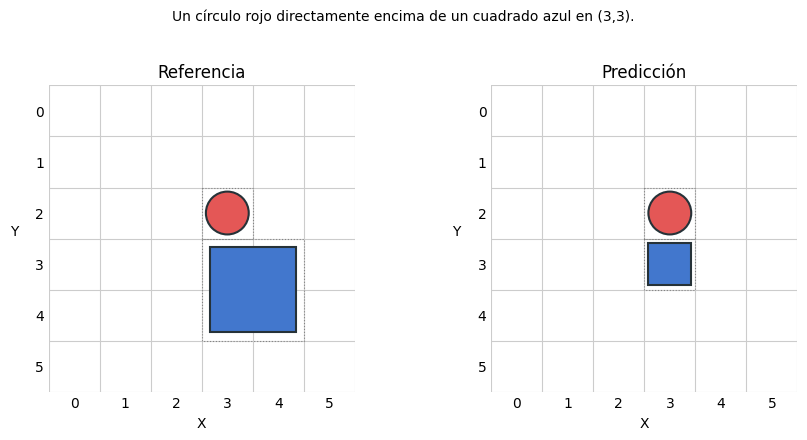

PROGRAMA ESPERADO:

CIRCLE RED 3 2 1
SQUARE BLUE 3 3 2


PROGRAMA GENERADO:

SQUARE BLUE 3 3 1
CIRCLE RED 3 2 1



In [10]:
# Ejemplo de evaluación y comparación entre dos salidas

program_gt = """
CIRCLE RED 3 2 1
SQUARE BLUE 3 3 2
"""

program_pred = """
SQUARE BLUE 3 3 1
CIRCLE RED 3 2 1
"""

example_df = pd.DataFrame({
    'id': [0], 'instruccion': ['Un círculo rojo directamente encima de un cuadrado azul en (3,3).'],
    'programa': [program_gt]
})

results = evaluate_predictions(example_df, [program_pred])
show_metrics(results)
compare_drawings(results)


### 0.4. Modelo de lenguaje

Utilizaremos [Qwen3.5-0.8B](https://huggingface.co/Qwen/Qwen3.5-0.8B), el LLM preentrenado más chico de la familia de modelos Qwen 3.5.

Se proporciona la carga del modelo y una función general para generar una respuesta a partir de una lista de mensajes. Cada mensaje es un diccionario de la forma `{'role': 'system' | 'user' | 'assistant', 'content': texto}`.


In [11]:
import torch

# Compatibilidad local Mac Intel (torch 2.2.x + transformers 5.2). En Colab no hace nada.
import torch_compat_macintel  # noqa: F401

import transformers
import peft
import accelerate
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = 'Qwen/Qwen3.5-0.8B'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# La T4 de Colab usa FP16, GPUs más nuevas pueden usar BF16.
DTYPE = (torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16) if DEVICE == 'cuda' else torch.float32
print('Modelo:', MODEL_NAME, '| Dispositivo:', DEVICE, '| Precisión:', DTYPE)
print('transformers:', transformers.__version__, '| torch:', torch.__version__)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype='auto', low_cpu_mem_usage=True,
    device_map='auto' if DEVICE == 'cuda' else None,
)

model = model.to(dtype=DTYPE)
model.eval()
print('Parámetros:', f'{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M')


Modelo: Qwen/Qwen3.5-0.8B | Dispositivo: cpu | Precisión: torch.float32
transformers: 5.2.0 | torch: 2.15.0+cpu


The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d
Loading weights: 100%|██████████| 320/320 [00:01<00:00, 273.29it/s, Materializing param=model.norm.weight]                              


Parámetros: 752.4 M


In [12]:
@torch.inference_mode()
def generate_response(messages, max_new_tokens=96):
    """Genera texto a partir de mensajes en formato chat de Hugging Face.

    Ejemplo de formato:
      [{'role': 'user', 'content': 'Hola'}]
    """
    inputs = tokenizer.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors='pt',
        enable_thinking=False,
    ).to(DEVICE)
    output = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
    )
    new_tokens = output[0, inputs['input_ids'].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


In [13]:
# Ejemplo de generación con el LLM
messages = [
    {'role': 'system', 'content': 'Sos un asistente útil.'},
    {'role': 'user', 'content': 'Hola'}
]
print(generate_response(messages))


¡Hola! ¿En qué puedo ayudarte hoy? Puedo asistirte en tareas como escribir, traducir, resolver problemas, crear contenido, analizar textos o simplemente conversar. ¿Hay algo específico en mente?


---

## Parte 1: Baseline zero-shot

Utilizando el modelo provisto, construir un sistema que transforme las instrucciones del dataset en programas de nuestro DSL mediante **zero-shot prompting**.

El prompt debe especificar la tarea y el formato esperado. Para cada instrucción, se deberá construir la conversación que se pasa a `generate_response(messages)`, obtener el programa predicho y evaluarlo utilizando las funciones provistas.

**Sugerencias:**
* Describir en el mensaje de sistema la gramática del DSL, las figuras, los colores, las coordenadas, la interpretación del tamaño y las restricciones de límites y colisiones.
* Solicitar únicamente el programa DSL, sin explicaciones ni bloques Markdown.
* Para pruebas rápidas puede utilizar un subconjunto pequeño de `dev`, pero reporte los resultados finales de esta parte sobre todo `dev` (120 ejemplos).

Evaluar la estrategia sobre el corpus de **dev**, imprimiendo validez, accuracy y F1 de objetos. Visualizar al menos **dos ejemplos** con errores y comentar qué fallos se observan.


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE 2 0 RED 2 0 TRIANGLE 2 0
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE BLUE 4 4\nTRIANGLE RED 1 4 4\nCIRCLE BL...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",FIGURA COLOR X Y TAMAÑO\nTRIANGLE 1 1 2\nCIRCL...
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",FIGURA COLOR X Y TAMAÑO.\nTRIANGLE YELLOW 1 1 ...
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",CIRCLE 1 2 1\nTRIANGLE 1 2 1\nSQUARE 2 3 2
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE 0 0 2\nCIRCLE 0 0 1\nCIRCLE 0 0 2
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",FIGURA COLOR X Y TAMAÑO\nSQUARE RED 3 3\nTRIAN...
117,"Dos figuras de una celda en columna 3, cuadrad...",CIRCLE 3 3 RED\nTRIANGLE 5 5 YELLOW
118,Acomodá en una franja vertical de ancho 2 desd...,FIGURA COLOR X Y TAMAÑO.\nSQUARE RED 2 2\nTRIA...


Baseline Zero-Shot (N = 120)
Validez:    0.0%
Accuracy:   0.0%
F1 objetos: 0.000


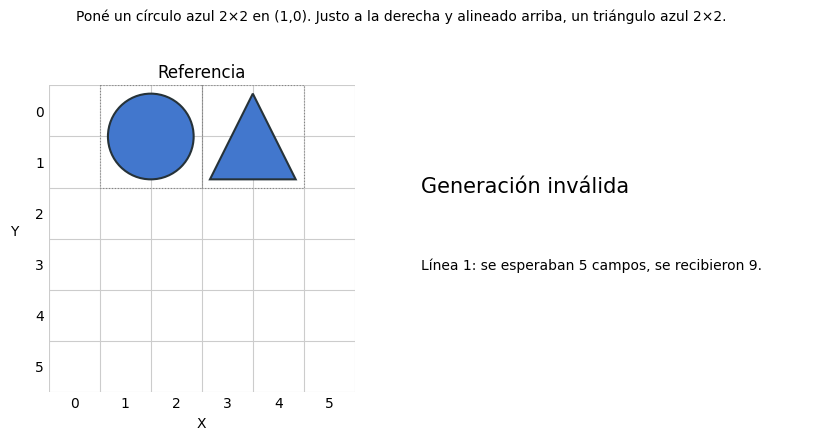

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE 2 0 RED 2 0 TRIANGLE 2 0


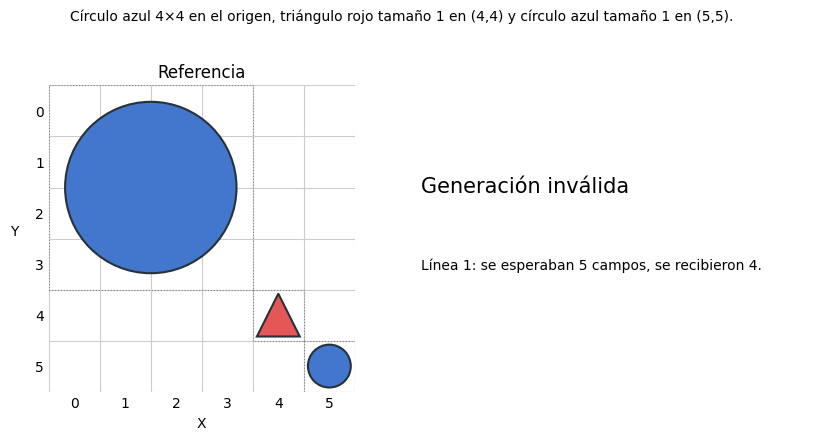

PROGRAMA ESPERADO:
CIRCLE BLUE 0 0 4
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1

PROGRAMA GENERADO:
CIRCLE BLUE 4 4
TRIANGLE RED 1 4 4
CIRCLE BLUE 1 5 5


In [14]:
# TODO (Parte 1):
# 1. Diseñar el prompt zero-shot.

train_zero_llm = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    # print(instruccion_actual)
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO. 
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo). 
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_zero_llm.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })
    

df_train_zero_llm = pd.DataFrame(train_zero_llm)
display(df_train_zero_llm)

resultados = evaluate_predictions(dev_df, df_train_zero_llm['programa_generado'])
show_metrics(resultados, name='Baseline Zero-Shot')

# Filtrar índices con errores (no exactos) y visualizar dos ejemplos:
errores_idx = resultados.index[~resultados['exacto']].tolist()
compare_drawings(resultados, index=errores_idx[0])
compare_drawings(resultados, index=errores_idx[1])

# 2. Construir la lista de mensajes para una instrucción.
# 3. Generar predicciones para dev_df (puede empezar con pocos ejemplos).
# 4. Obtener los resultados con evaluate_predictions(...) y show_metrics(...).
# 5. Visualizar errores con compare_drawings(...).


**Descripción del baseline y análisis de resultados:**

(Describa el prompt utilizado, indique las tres métricas y comente los errores observados.)

Aclaracion inicial: el desarrollo de este LAB fue asistido por IA para la construccion del código. Cuando se pudo generar codigo manualmente, eso fue priorizado. Las conclusiones fueron hechas casi sin asistencia de IA. 

Se probaron varios prompts, tartando de corregir los errores encontrados con el prompt anterior. Sin embargo los resultados no fueron muy buenos. Los "programas" se asemejaban cada vez mas al programa esperado, pero siembre se encontraron errores que hicieron que el programa no sea exactamente como se esperaba. Alguno de las lineas del programa se ajustaba a lo esperado, pero no logramos que todas lo hicieran. 


---

## Parte 2: Estrategias de prompting

Diseñar y evaluar al menos **tres estrategias diferentes de prompting** adicionales al baseline de la Parte 1. Para cada una, describir la idea, implementar la estrategia, evaluarla en `dev` y comparar los resultados con zero-shot.

Se **recomienda que al menos una de las estrategias sea few-shot prompting**: incluir ejemplos resueltos tomados de `train` en los mensajes que recibe el modelo. Las otras dos estrategias quedan a elección.

**Posibles alternativas para explorar:**
* Variar la cantidad o selección de ejemplos few-shot, sin utilizar `dev` ni `test` para las demostraciones.
* Mejorar las reglas, instrucciones y organización del prompt de sistema.
* Diseñar un procedimiento de generación y corrección: por ejemplo, verificar si la salida cumple el DSL y solicitar una nueva generación cuando sea inválida.
* También es válido variar aspectos como el modelo, parámetros del decoding, razonamiento, utilizar generación estructurada, o realizar múltiples llamadas al modelo.

Se debe reportar una tabla comparativa entre el baseline zero-shot y las nuevas estrategias, e identificar la mejor configuración utilizando **accuracy en `dev`**. Analizar también la validez y F1 de objetos.


### Estrategia 1

Describa aquí la estrategia de prompting que quiere probar. Se recomienda comenzar con few-shot prompting.


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE BLUE 0 0 1\nTRIANGLE BLUE 1 1 2
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE RED 0 0 1\nTRIANGLE RED 4 4 1\nCIRCLE B...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",TRIANGLE YELLOW 0 3 2\nCIRCLE YELLOW 0 3 3
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",TRIANGLE YELLOW 1 1 3 TRIANGLE RED 1 5 1
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",SQUARE GREEN 1 2 1\nTRIANGLE BLUE 1 3 1\nSQUAR...
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE GREEN 3 2 2 1 2 4
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",SQUARE YELLOW 2 1 3\nTRIANGLE 1 4 1\nTRIANGLE ...
117,"Dos figuras de una celda en columna 3, cuadrad...",SQUARE GREEN 3 3 TRIANGLE YELLOW 5 5 1 2 3 4 5...
118,Acomodá en una franja vertical de ancho 2 desd...,SQUARE YELLOW 3 0 2\nTRIANGLE BLUE 3 2 2\nCIRC...


Estrategia 1: One-Shot (N = 120)
Validez:    47.5%
Accuracy:   14.2%
F1 objetos: 0.253


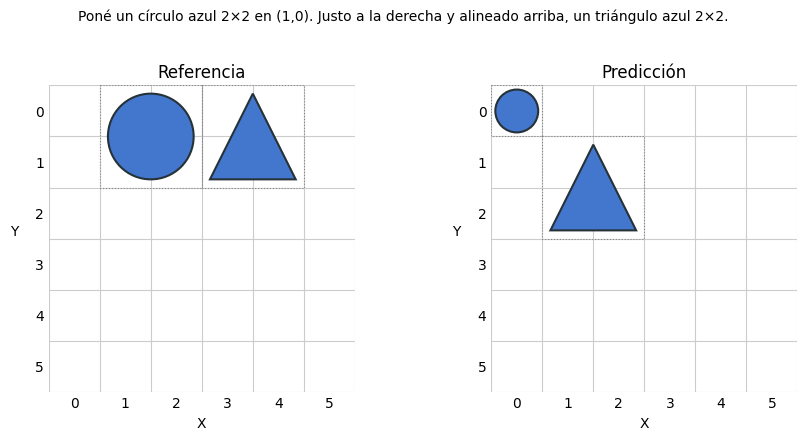

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 0 0 1
TRIANGLE BLUE 1 1 2


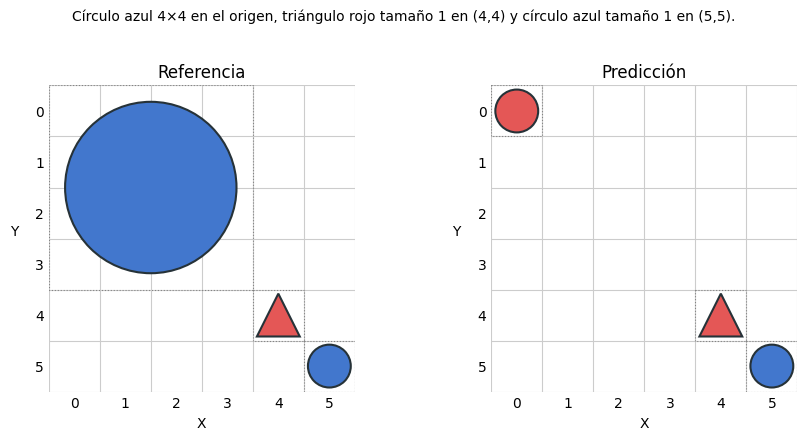

PROGRAMA ESPERADO:
CIRCLE BLUE 0 0 4
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1

PROGRAMA GENERADO:
CIRCLE RED 0 0 1
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1


In [15]:
# TODO (Estrategia 1): implementar el prompt y generar/evaluar sobre dev_df. 
# ONE SHOT
one_shot_example = {
    'instruccion': 'Colocá un círculo rojo en la esquina superior izquierda.',
    'programa': 'CIRCLE RED 0 0 1'
}

train_llm_one_shot = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    # print(instruccion_actual)
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO. 
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo). 
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': one_shot_example['instruccion']},
        {'role': 'assistant', 'content': one_shot_example['programa']},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_llm_one_shot.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })
    
    # print('\nPrograma generado:')
    # print(programa_generado)
    # print('\nPrograma de referencia:')
    # print(dev_df.iloc[i]['programa'])
    

df_train_llm_one_shot = pd.DataFrame(train_llm_one_shot)
display(df_train_llm_one_shot)

resultados_one_shot = evaluate_predictions(dev_df, df_train_llm_one_shot['programa_generado'])
show_metrics(resultados_one_shot, name='Estrategia 1: One-Shot')

errores_idx_os = resultados_one_shot.index[~resultados_one_shot['exacto']].tolist()
if len(errores_idx_os) >= 2:
    compare_drawings(resultados_one_shot, index=errores_idx_os[0])
    compare_drawings(resultados_one_shot, index=errores_idx_os[1])


**Resultados y observaciones (estrategia 1): One Shot**

Aqui los resultados mejoraron notoriamente frente a la estrategia Zero-Shot. 
Se agrego al prompt, en modo assistant,  1 ejemplo de pregunta/respuesta que guió al LLM a mejor performance. 

Estrategia 1: One-Shot (N = 120)
Validez:    47.5%
Accuracy:   14.2%
F1 objetos: 0.253

### Estrategia 2

Describa la nueva estrategia y cómo se diferencia de las anteriores.


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE BLUE 1 0 2\nTRIANGLE BLUE 1 1 2
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE BLUE 4 4 1\nTRIANGLE RED 4 4 1\nCIRCLE ...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",TRIANGLE YELLOW 2 3 2\nCIRCLE YELLOW 3 3 3
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",TRIANGLE YELLOW 2 2 3\nTRIANGLE YELLOW 2 2 1\n...
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",SQUARE GREEN 1 1 1\nTRIANGLE BLUE 1 2 1\nSQUAR...
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE GREEN 3 2 2\nCIRCLE GREEN 3 4 1
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",SQUARE YELLOW 3 3 2 1 TRIANGLE RED 4 4 1 TRIAN...
117,"Dos figuras de una celda en columna 3, cuadrad...",SQUARE GREEN 3 3 2\nTRIANGLE YELLOW 3 5 3
118,Acomodá en una franja vertical de ancho 2 desd...,SQUARE YELLOW 2 2 2\nTRIANGLE BLUE 2 2 2\nCIRC...


Estrategia 2: Few-Shot (3 ejemplos) (N = 120)
Validez:    56.7%
Accuracy:   25.0%
F1 objetos: 0.341


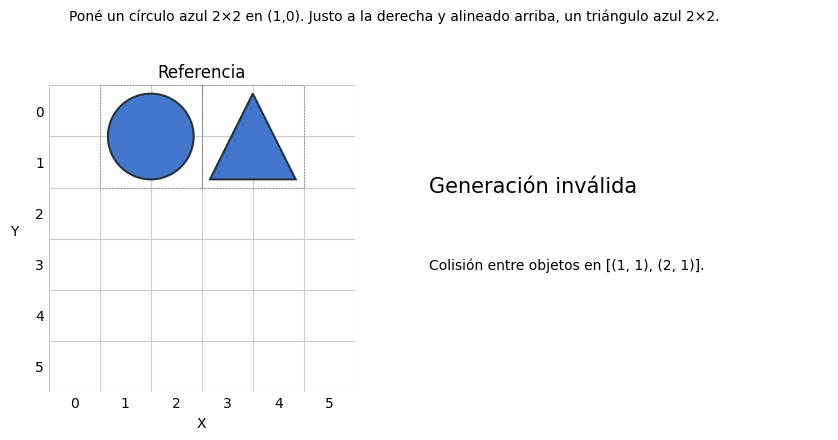

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 1 1 2


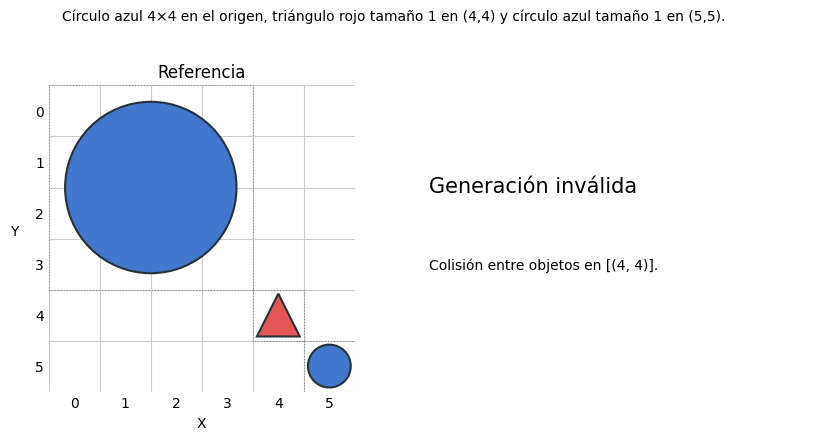

PROGRAMA ESPERADO:
CIRCLE BLUE 0 0 4
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1

PROGRAMA GENERADO:
CIRCLE BLUE 4 4 1
TRIANGLE RED 4 4 1
CIRCLE BLUE 5 5 1


In [16]:
# TODO (Estrategia 2): implementar el prompt y generar/evaluar sobre dev_df. FEW SHOT
few_shot_examples = [
    {
        'instruccion': 'Colocá un círculo rojo en el origen.',
        'programa': 'CIRCLE RED 0 0 1'
    },
    {
        'instruccion': 'Colocá un cuadrado azul de tamaño 2 en la esquina inferior derecha.',
        'programa': 'SQUARE BLUE 4 4 2'
    }, 
    {
        'instruccion': 'Colocá un triángulo verde de tamaño 3 en el centro.',
        'programa': 'TRIANGLE GREEN 2 2 3'
    }
]

train_llm_few_shot = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    # print(instruccion_actual)
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO. 
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo). 
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': few_shot_examples[0]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples[0]['programa']},
        {'role': 'user', 'content': few_shot_examples[1]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples[1]['programa']},
        {'role': 'user', 'content': few_shot_examples[2]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples[2]['programa']},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_llm_few_shot.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })

df_train_llm_few_shot = pd.DataFrame(train_llm_few_shot)
display(df_train_llm_few_shot)

resultados_few_shot = evaluate_predictions(dev_df, df_train_llm_few_shot['programa_generado'])
show_metrics(resultados_few_shot, name='Estrategia 2: Few-Shot (3 ejemplos)')

errores_idx_fs = resultados_few_shot.index[~resultados_few_shot['exacto']].tolist()
if len(errores_idx_fs) >= 2:
    compare_drawings(resultados_few_shot, index=errores_idx_fs[0])
    compare_drawings(resultados_few_shot, index=errores_idx_fs[1])


**Resultados y observaciones (estrategia 2): Few-Shot**
Aqui los resultados mejoraron notoriamente frente a la estrategia One-shot. 
Se agrego al prompt, en modo assistant,  3 ejemplos de pregunta/respuesta que guió al LLM a mejor performance. 

Estrategia 1: One-Shot (N = 120)
Validez:    47.5%
Accuracy:   14.2%
F1 objetos: 0.253

Estrategia 2: Few-Shot (3 ejemplos) (N = 120)
Validez:    56.7%
Accuracy:   25.0%
F1 objetos: 0.341


### Estrategia 3

Describa la nueva estrategia y cómo se diferencia de las anteriores.


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE BLUE 1 0 2\nTRIANGLE BLUE 1 0 2
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE BLUE 0 0 4\nTRIANGLE RED 4 4 1\nCIRCLE ...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",TRIANGLE YELLOW 0 3 2 SQUARE YELLOW 0 3 3
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",TRIANGLE YELLOW 1 1 3\nTRIANGLE RED 5 5 1\nSQU...
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",SQUARE GREEN 1 2 1\nTRIANGLE BLUE 2 3 1\nSQUAR...
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE GREEN 3 2 2\nCIRCLE GREEN 3 4 1
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",SQUARE YELLOW 2 1 3\nTRIANGLE GREEN 2 1 1\nTRI...
117,"Dos figuras de una celda en columna 3, cuadrad...",CIRCLE RED 3 0 1\nSQUARE BLUE 3 3 2\nTRIANGLE ...
118,Acomodá en una franja vertical de ancho 2 desd...,SQUARE YELLOW 3 0 2 TRIANGLE BLUE 3 2 2 CIRCLE...


Estrategia 3: Chain of Thought (N = 120)
Validez:    62.5%
Accuracy:   49.2%
F1 objetos: 0.550


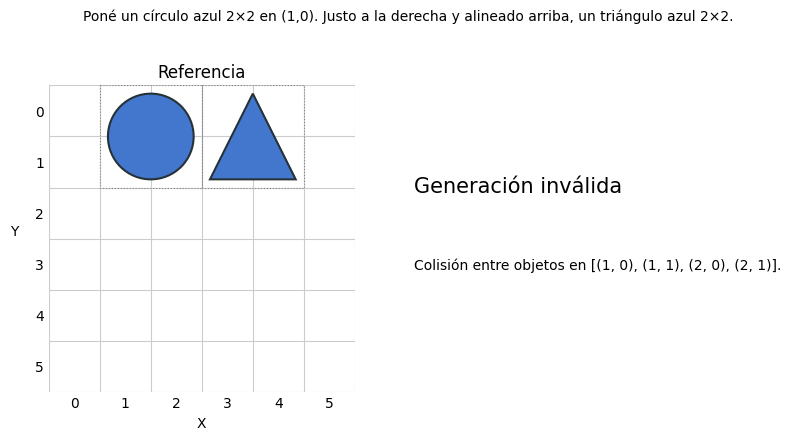

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 1 0 2


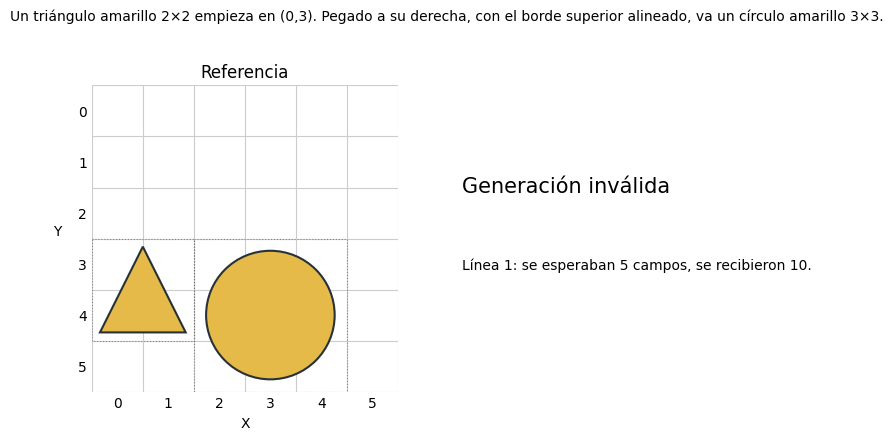

PROGRAMA ESPERADO:
TRIANGLE YELLOW 0 3 2
CIRCLE YELLOW 2 3 3

PROGRAMA GENERADO:
TRIANGLE YELLOW 0 3 2 SQUARE YELLOW 0 3 3


In [17]:
# TODO (Estrategia 3): implementar el prompt y generar/evaluar sobre dev_df. Chain of Thought (CoT)
cot_examples = [
    {
        'instruccion': 'Colocá un círculo rojo en el origen.',
        'razonamiento': 'El origen tiene coordenadas (0,0). Queremos un círculo rojo de tamaño 1.',
        'programa': 'CIRCLE RED 0 0 1'
    },
    {
        'instruccion': 'Colocá un cuadrado azul de tamaño 2 en la esquina inferior derecha.',
        'razonamiento': 'La esquina inferior derecha tiene coordenadas (4,4). Queremos un cuadrado azul de tamaño 2.',
        'programa': 'SQUARE BLUE 4 4 2'
    },
    {
        'instruccion': 'Colocá un triángulo verde de tamaño 3 en el centro.',
        'razonamiento': 'El centro tiene coordenadas (2,2). Queremos un triángulo verde de tamaño 3.',
        'programa': 'TRIANGLE GREEN 2 2 3'
    }
]

train_llm_cot = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO. 
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo). 
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': cot_examples[0]['instruccion']},
        {'role': 'assistant', 'content': cot_examples[0]['razonamiento']},
        {'role': 'assistant', 'content': cot_examples[0]['programa']},
        {'role': 'user', 'content': cot_examples[1]['instruccion']},
        {'role': 'assistant', 'content': cot_examples[1]['razonamiento']},
        {'role': 'assistant', 'content': cot_examples[1]['programa']},
        {'role': 'user', 'content': cot_examples[2]['instruccion']},
        {'role': 'assistant', 'content': cot_examples[2]['razonamiento']},
        {'role': 'assistant', 'content': cot_examples[2]['programa']},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_llm_cot.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })

df_train_llm_cot = pd.DataFrame(train_llm_cot)
display(df_train_llm_cot[['instruccion', 'programa_generado']])

resultados_cot = evaluate_predictions(dev_df, df_train_llm_cot['programa_generado'])
show_metrics(resultados_cot, name='Estrategia 3: Chain of Thought')

errores_idx_cot = resultados_cot.index[~resultados_cot['exacto']].tolist()
if len(errores_idx_cot) >= 2:
    compare_drawings(resultados_cot, index=errores_idx_cot[0])
    compare_drawings(resultados_cot, index=errores_idx_cot[1])


**Resultados y observaciones (estrategia 3):implementar el prompt y generar/evaluar sobre dev_df. Chain of Thought (CoT)**

Aqui los resultados mejoraron notoriamente frente a la estrategia One-shot y frente a few shot. 
Se agrego al prompt, en modo assistant,  3 ejemplos de pregunta/ razonamiento /respuesta que guió al LLM a mejor performance. 

Estrategia 1: One-Shot (N = 120)
Validez:    47.5%
Accuracy:   14.2%
F1 objetos: 0.253

Estrategia 2: Few-Shot (3 ejemplos) (N = 120)
Validez:    56.7%
Accuracy:   25.0%
F1 objetos: 0.341

Estrategia 3: Chain of Thought (N = 120)
Validez:    62.5%
Accuracy:   49.2%
F1 objetos: 0.550


,instruccion,programa_generado
0,"Poné un círculo azul 2×2 en (1,0). Justo a la ...",CIRCLE BLUE 1 0 2\nTRIANGLE BLUE 1 0 2
1,"Círculo azul 4×4 en el origen, triángulo rojo ...",CIRCLE BLUE 0 0 4\nTRIANGLE RED 4 4 1\nCIRCLE ...
2,"Un triángulo amarillo 2×2 empieza en (0,3). Pe...",TRIANGLE YELLOW 0 3 2\nCIRCLE YELLOW 0 3 3
3,"Triángulos amarillos, tamaño 3 en (1,1) y tama...",TRIANGLE YELLOW 1 1 3\nTRIANGLE YELLOW 4 4 1\n...
4,"Me gustaría un cuadrado verde tamaño 1 en (1,2...",SQUARE GREEN 1 2 1\nTRIANGLE BLUE 2 3 1\nSQUAR...
...,...,...
115,Círculos verdes con columna inicial 3: tamaño ...,CIRCLE GREEN 3 2 2\nCIRCLE GREEN 3 4 1
116,"Cuadrado amarillo 3×3 desde (2,1). En fila 4, ...",SQUARE YELLOW 3 1 3\nTRIANGLE YELLOW 4 4 1\nTR...
117,"Dos figuras de una celda en columna 3, cuadrad...",SQUARE GREEN 3 3 3\nTRIANGLE YELLOW 5 5 1
118,Acomodá en una franja vertical de ancho 2 desd...,SQUARE YELLOW 2 0 2\nTRIANGLE BLUE 2 2 2\nCIRC...


Estrategia 4: Few-Shot (3 ejemplos de train df) (N = 120)
Validez:    75.8%
Accuracy:   52.5%
F1 objetos: 0.603


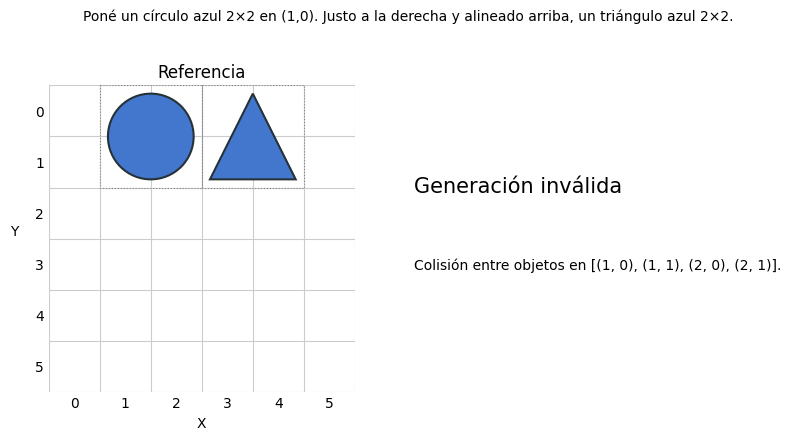

PROGRAMA ESPERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 3 0 2

PROGRAMA GENERADO:
CIRCLE BLUE 1 0 2
TRIANGLE BLUE 1 0 2


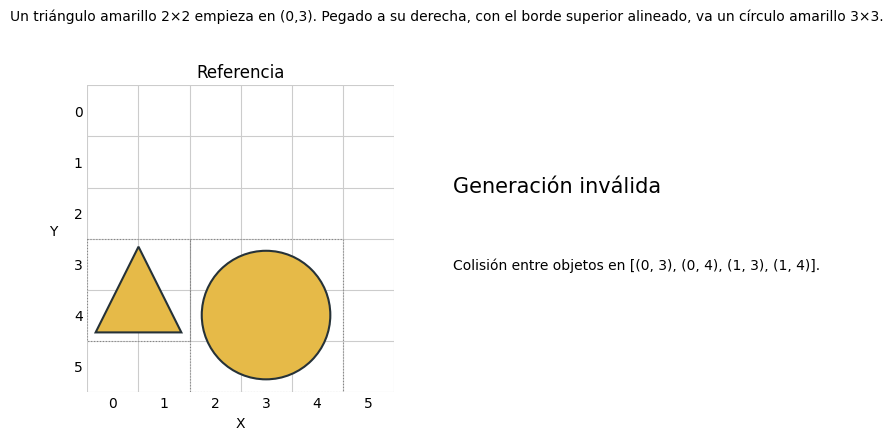

PROGRAMA ESPERADO:
TRIANGLE YELLOW 0 3 2
CIRCLE YELLOW 2 3 3

PROGRAMA GENERADO:
TRIANGLE YELLOW 0 3 2
CIRCLE YELLOW 0 3 3


In [19]:
# Estrategia 4 Few shot usando ejemplos de Dataset de Training
few_shot_examples_train = [
    {
        'instruccion': train_df.iloc[0]['instruccion'],
        'programa': train_df.iloc[0]['programa']
    },
    {
        'instruccion': train_df.iloc[1]['instruccion'],
        'programa': train_df.iloc[1]['programa']
    }, 
    {
        'instruccion': train_df.iloc[2]['instruccion'],
        'programa': train_df.iloc[2]['programa']
    }
]

train_llm_few_shot_train = []

for i in range(dev_df.shape[0]):
    instruccion_actual = dev_df.iloc[i]['instruccion']
    # print(instruccion_actual)
    messages = [
        {'role': 'system', 'content': """Traducí la instrucción a un programa en texto plano. Cada objeto debe escribirse en una línea separada con exactamente 5 campos separados por un espacio y en este orden explicito:
        FIGURA COLOR X Y TAMAÑO. 
        Para cada campo, los valores permitidos son:
        Para FIGURA: se aceptan SOLO los valores: CIRCLE (círculo), SQUARE (cuadrado), TRIANGLE (triángulo). 
        Para COLOR: se aceptan SOLO los valores: RED (rojo), BLUE (azul), GREEN (verde), YELLOW (amarillo).
        Para X: se aceptan SOLO enteros de 0 a 5 (columna de la esquina superior izquierda; 0 es izquierda, crece hacia la derecha)
        Para Y: se aceptan SOLO enteros de 0 a 5 (fila de la esquina superior izquierda; 0 es arriba, crece hacia abajo)
        Para TAMAÑO: se aceptan SOLO enteros de 1 a 6 (el objeto ocupa TAMAÑO x TAMAÑO celdas hacia la derecha y hacia abajo)

        Restricciones:
        Todo objeto debe caber en el tablero de 6x6, es decir que X + TAMAÑO <= 6 e Y + TAMAÑO <= 6.
        Entre 1 y 3 objetos por escena, sin superponerse.
        Respondé ÚNICAMENTE con las líneas del programa en texto plano. No uses bloques de código Markdown (```), ni HTML/SVG, ni agregues explicaciones. """},
        {'role': 'user', 'content': few_shot_examples_train[0]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples_train[0]['programa']},
        {'role': 'user', 'content': few_shot_examples_train[1]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples_train[1]['programa']},
        {'role': 'user', 'content': few_shot_examples_train[2]['instruccion']},
        {'role': 'assistant', 'content': few_shot_examples_train[2]['programa']},
        {'role': 'user', 'content': instruccion_actual},
    ]
    programa_generado = generate_response(messages)
    train_llm_few_shot_train.append({
        'instruccion': instruccion_actual,
        'programa_generado': programa_generado,
    })

df_train_llm_few_shot_train = pd.DataFrame(train_llm_few_shot_train)
display(df_train_llm_few_shot_train)

resultados_few_shot_train = evaluate_predictions(dev_df, df_train_llm_few_shot_train['programa_generado'])
show_metrics(resultados_few_shot_train, name='Estrategia 4: Few-Shot (3 ejemplos de train df)')

errores_idx_fs = resultados_few_shot_train.index[~resultados_few_shot_train['exacto']].tolist()
if len(errores_idx_fs) >= 2:
    compare_drawings(resultados_few_shot_train, index=errores_idx_fs[0])
    compare_drawings(resultados_few_shot_train, index=errores_idx_fs[1])


**Resultados y observaciones (estrategia 4):Few shot usando ejemplos de Dataset de Training**

Aqui los resultados mejoraron notoriamente frente a la estrategia las demas estrategias.  
Se agrego al prompt, en modo assistant,  3 ejemplos de pregunta/respuesta usando 3 pares de preguntas/respuestas del data set de train.

Estrategia 1: One-Shot (N = 120)
Validez:    47.5%
Accuracy:   14.2%
F1 objetos: 0.253

Estrategia 2: Few-Shot (3 ejemplos) (N = 120)
Validez:    56.7%
Accuracy:   25.0%
F1 objetos: 0.341

Estrategia 3: Chain of Thought (N = 120)
Validez:    62.5%
Accuracy:   49.2%
F1 objetos: 0.550

Estrategia 4: Few-Shot (3 ejemplos de train df) (N = 120)
Validez:    75.8%
Accuracy:   52.5%
F1 objetos: 0.603

Éstos fueron los mejores resultados obtenidos. 


### Comparación de las estrategias

Construya una tabla con las métricas obtenidas por las alternativas exploradas (zero-shot y las nuevas estrategias), e incluya el análisis de al menos **dos errores** de su mejor estrategia.


,Validez (%),Accuracy (%),F1 objetos
Estrategia,,,
Baseline Zero-Shot,0.0,0.0,0.000
Estrategia 1: One-Shot,47.5,14.2,0.253
Estrategia 2: Few-Shot (3 ej. manuales),56.7,25.0,0.341
Estrategia 3: Chain of Thought (CoT),62.5,49.2,0.550
Estrategia 4: Few-Shot (3 ej. de train),75.8,52.5,0.603


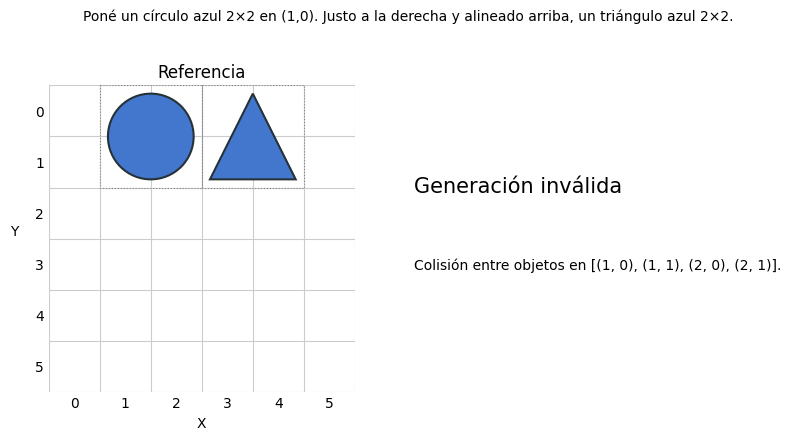

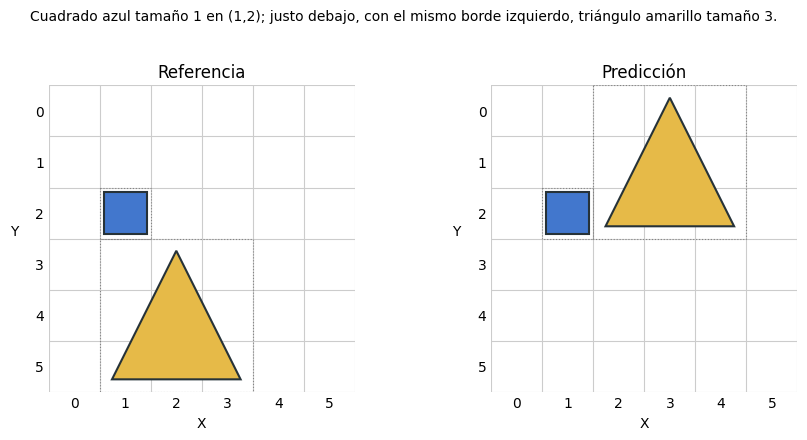

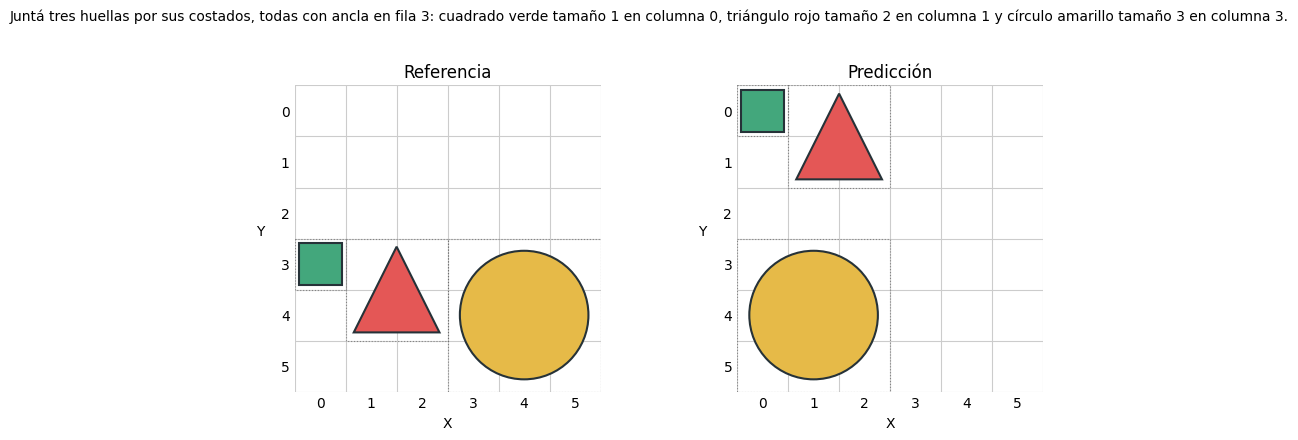

In [23]:
# Construir la tabla de resultados de la Parte 1 y las 4 nuevas estrategias
import sys
if not hasattr(sys.stdout, "pub_thread") and hasattr(sys.stderr, "pub_thread"):
    from ipykernel.iostream import OutStream
    sys.stdout = OutStream(sys.stderr.session, sys.stderr.pub_thread, "stdout")

experimentos = [
    ("Baseline Zero-Shot", resultados),
    ("Estrategia 1: One-Shot", resultados_one_shot),
    ("Estrategia 2: Few-Shot (3 ej. manuales)", resultados_few_shot),
    ("Estrategia 3: Chain of Thought (CoT)", resultados_cot),
    ("Estrategia 4: Few-Shot (3 ej. de train)", resultados_few_shot_train),
]

filas_comparativas = []
for nombre, df_res in experimentos:
    filas_comparativas.append({
        "Estrategia": nombre,
        "Validez (%)": round(df_res["valido"].mean() * 100, 1),
        "Accuracy (%)": round(df_res["exacto"].mean() * 100, 1),
        "F1 objetos": round(df_res["f1_objetos"].mean(), 3),
    })

df_comparativo = pd.DataFrame(filas_comparativas).set_index("Estrategia")
display(df_comparativo)

# Identificar la mejor estrategia (mayor Validez y Accuracy: Estrategia 4)
mejor_nombre, mejor_res = max(
    experimentos,
    key=lambda x: (x[1]["valido"].mean(), x[1]["exacto"].mean())
)
print(f"\nMejor estrategia: {mejor_nombre}")

# Visualizar errores de la mejor estrategia:
# 1) Errores de colisión/sintaxis (inválidos) y 2) Errores con programa válido pero escena inexacta
errores_invalidos = mejor_res.index[~mejor_res["valido"]].tolist()
errores_validos = mejor_res.index[mejor_res["valido"] & ~mejor_res["exacto"]].tolist()

print(f"Total de errores en {mejor_nombre}: {len(errores_invalidos) + len(errores_validos)} "
      f"({len(errores_invalidos)} inválidos, {len(errores_validos)} válidos pero inexactos)\n")

# Mostramos un error inválido (colisión) y dos errores con programa válido pero escena incorrecta
for idx in (errores_invalidos[:1] + errores_validos[:2]):
    print(f"--- Ejemplo con error (índice dev={idx}, id={mejor_res.loc[idx, 'id']}, válido={mejor_res.loc[idx, 'valido']}) ---")
    compare_drawings(mejor_res, index=idx)

**Análisis comparativo:**

Los mejores resultados fueron los obtenidos en la estrategia 4. 

	                                    Validez (%)	Accuracy (%)	F1 objetos
Estrategia			
Baseline Zero-Shot	                    0.0	        0.0	            0.000
Estrategia 1: One-Shot	                47.5	    14.2	        0.253
Estrategia 2: Few-Shot (3 ej. manuales)	56.7	    25.0	        0.341
Estrategia 3: Chain of Thought (CoT)	62.5	    49.2	        0.550
Estrategia 4: Few-Shot (3 ej. de train)	75.8	    52.5	        0.603

La validez de los programas es muy buena, sin embargo la accuracy todavia apenas supera el 50%.
Posiblemente si elijo mas cuidadosamente los ejemplos del few shot para que contemplen mas "casos diferentes" va a mejorar la performanc general. 

---

## Parte 3: Fine-tuning mediante LoRA

Utilizando `train`, realizar un **fine-tuning supervisado de Qwen3.5-0.8B con LoRA** para adaptar el modelo a la tarea de generación de programas DSL.

El entrenamiento deberá utilizar los pares `(instruccion, programa)` de `train`: la entrada del usuario es la instrucción en español y la respuesta esperada del asistente es el programa DSL correspondiente.

**Sugerencias:**
* Utilizar [`LoraConfig` y `get_peft_model`](https://huggingface.co/docs/peft/main/package_reference/lora) de PEFT para adaptar el modelo y [`Trainer` / `TrainingArguments`](https://huggingface.co/docs/transformers/main/main_classes/trainer) para el entrenamiento supervisado.
* En Qwen3.5, `target_modules='all-linear'` permite seleccionar proyecciones lineales sin depender de los nombres internos de las capas.
* Utilizar un prompt de entrenamiento consistente con el que se utilizará para generar durante la evaluación.


### 3.1. Preparación de los datos supervisados

Construya los ejemplos de entrenamiento con el chat template del tokenizador.


In [ ]:
# TODO (Parte 3): construir Dataset con conversaciones (mensajes) para cada ejemplo de train_df, usando el chat template de Qwen.


### 3.2. Configuración y entrenamiento de LoRA

Implemente y ejecute el fine-tuning. Se recomienda guardar los adaptadores LoRA para no tener que repetir el entrenamiento al retomar el notebook.


In [ ]:
# TODO: crear LoraConfig, adaptar el modelo y configurar Trainer.


In [ ]:
# TODO: ejecutar el entrenamiento.


**Descripción del modelo entrenado:**

(Indique la configuración de LoRA y los hiperparámetros utilizados)

...


### 3.3. Evaluación en dev

Utilizando el modelo adaptado, generar programas para los **120 ejemplos de `dev`**, sin incluir demostraciones few-shot salvo que desee estudiar explícitamente esa combinación. Reportar las tres métricas y comparar los resultados con la mejor estrategia de prompting de la Parte 2.

Analice al menos **dos errores** del modelo adaptado visualizando la escena esperada y la predicha.


In [ ]:
# TODO: generar predicciones con el modelo adaptado.
# TODO: evaluar con evaluate_predictions(...) y show_metrics(...).
# TODO: visualizar y analizar al menos dos ejemplos erróneos.


**Resultados y comparación con prompting:**

...


---

### Evaluación final: test y test OOD

Una vez terminados los experimentos y seleccionada la mejor estrategia de prompting y realizado el fine-tuning LoRA, usando únicamente `dev`, realice las siguientes evaluaciones en orden:

1. **Test (dentro de distribución):** Evalúe ambas estrategias sobre los 120 ejemplos de `test_df`. Reporte validez, accuracy y F1 de objetos.

2. **Test OOD (fuera de distribución):** Evalúe ambas estrategias sobre los 50 ejemplos de `test_ood_df`. Reporte las mismas tres métricas.

Compare los resultados de ambas particiones y discuta las diferencias. ¿Los métodos generalizan bien a escenas diferentes?


In [ ]:
# TODO: evaluar sobre test_df las dos estrategias seleccionadas usando
# exclusivamente los prompts, ejemplos e hiperparámetros elegidos en dev.


In [ ]:
# TODO: evaluar sobre test_ood_df las dos estrategias seleccionadas usando
# exclusivamente los prompts, ejemplos e hiperparámetros elegidos en dev.


### Análisis de resultados

Analice los resultados obtenidos y responda, al menos, las siguientes preguntas:

1. **¿Qué estrategia de prompting funcionó mejor?** Describa brevemente cómo se construyó, qué cambió respecto a zero-shot y qué resultados obtuvo.
2. **¿Qué aportó el fine-tuning con LoRA?** Compare los resultados con prompting, incluyendo las diferencias entre validez de DSL, accuracy y F1 de objetos.
3. **¿Qué diferencias aparecen entre `test` y `test_ood`?** Compare las tres métricas para cada estrategia. ¿Hay una caída de rendimiento? ¿Es similar para prompting y LoRA?
4. **¿En qué tipos de ejemplos OOD falla más el modelo?** Analice ejemplos concretos, tanto de escenas reales como de escenas con más de tres objetos.

**Sus respuestas aquí:**

...
